# TUTORIAL: Real-time bias-aware data assimilation
<script src='https://cdnjs.cloudflare.com/ajax/libs/mathjax/2.7.4/MathJax.js?config=default'></script>

* [What is bias-aware data assimilation?](#BADA)
    * [The source of bias: model accuracy vs computational cost](#source)
    * [Algorithmic view on bias-aware data assimilation](#algo)
* [What is bias-aware data assimilation, a bit more technically?](#tech)
    * [Aleatoric and epistemic uncertainties](#UQ)
    * [Augmented state-space formulation](#augment)
    * [Model bias in a stochastic ensemble framework](#bias-stoch)
    * [How do we estimate the bias in time?](#evolution)
* [The regularized ensemble Kalman filter](#rEnKF)
    * [Test case: van der Pol model with manually added bias](#test)
 


<a class="anchor" id="BADA"></a>
# 1. What is bias-aware data assimilation? 
Real-time data assimilation combines quick estimates of a physical state from an numerical model with experimental data.  In reality, numerical models are not a perfect representation of the physical quantity which we aim to predict because they typically rely on assumptions and simplifications for computational, i.e, they have an inherent model bias.

<br /> 

<a class="anchor" id="source"></a>
## 1.1. The source of bias: model accuracy vs computational cost 

The choice of physical model plays a key role in the assimilation. Numerical models are mathematical representations of the processes that govern the behaviour of a physical system. For example, in weather forecasting, models simulate how the atmosphere evolves over time based on physical equations describing fluid dynamics, thermodynamics, etc. The more physical information we add to the model, the higher the accuracy of the model estimates. However, the computational requirements increase with the model complexity.

To perform real-time data assimilation we need quick estimates of the physical system. Thus, performing real-time high-fidelity modelling is not plausible in realistic scenarios. In order to apply real-time data assimilation to low-fidelity models, we must provide an estimate of the bias in the numerical model, i.e., the model error that we introduce when simplifying the physical equations.  

<a><img src="../../docs/figs/DA/models_pyramid.png" width=600px></a>



<a class="anchor" id="algo"></a>
## 1.2. Algorithmic view on bias-aware data assimilation 

Algorithmically, we can summarize the bias-aware data assimilation process as:
1. <em>Forecast</em>: propagate the imperfect numerical model in time to provide a <strong><font color="#e0915c">biased forecast</font></strong> when <strong><font color="#24678d">observation</font></strong> data become available.
2. <em>Bias correction</em>: provide an estimate the bias, and project the <strong><font color="#e0915c">biased forecast</font></strong> into an <strong><font color="#a561d0">unbiased forecast</font></strong><font color="#2a2a2a"></font>. 
3. <em>Assimilation</em>: combine optimally the <strong><font color="#a561d0">unbiased forecast</font></strong> with the <strong><font color="#24678d">observations</font></strong>. The direct assimilation results in an <strong><font color="#91e05c">unbiased analysis</font></strong>, and the <strong><font color="#76cae9">biased analysis</font></strong> is an indirect by-product of the assimilation.
4. <em>Update</em>: the <strong><font color="#76cae9">biased analysis</font></strong> is the initial condition for the new forecast step.

<a><img src="../../docs/figs/DA/wBADA.gif" width=800px></a> 

<br /> 

<a class="anchor" id="tech"></a>
# 2. What is bias-aware data assimilation, a bit more technically? 

In this section, we revisit the formulation of the stochastic framework introduced in tutorial ***11_ensemble-DA_intro.ipynb*** and we extend it to account for model biases. 

<br />
<a class="anchor" id="UQ"></a>

## 2.1. Aleatoric and epistemic uncertainties  
 

First, we discuss the statistical hypotheses on the aleatoric uncertainties. The aleatoric uncertainties contaminate the state and parameters as 

$$
     \boldsymbol{\phi}  +  \boldsymbol{\epsilon}_\phi =  \boldsymbol{\phi}^\dagger, \quad
     \boldsymbol{\alpha} +  \boldsymbol{\epsilon}_\alpha =  \boldsymbol{\alpha}^\dagger,
$$

where $\dagger$ indicates the true quantity (which is unknown). The aleatoric uncertainties are modelled as Gaussian distributions   

$$
     \boldsymbol{\epsilon}_\phi \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{\phi\phi} ), \quad  \boldsymbol{\epsilon}_\alpha \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{\alpha\alpha} ),
$$

where $\mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}})$ is a normal distribution with zero mean and covariance $\boldsymbol{\mathsf{C}}$. Second, we discuss model biases, which are epistemic uncertainties. The model bias is defined as the expected difference between the true observable and the model observable, i.e., 

$$
   \boldsymbol{b}   =  \boldsymbol{d}^{\dagger} -\mathbb{E}( \boldsymbol{q}). 
$$

Hence, the bias-corrected model observable is

$$
     \boldsymbol{y} =  \boldsymbol{q} +  \boldsymbol{b} +  \boldsymbol{\epsilon}_q, 
$$

where $\boldsymbol{\epsilon}_q \sim \mathcal{N}( \boldsymbol{0},  \boldsymbol{\mathsf{C}}_{qq})$. (If the model is unbiased, $\boldsymbol{d}^{\dagger} =\mathbb{E}( \boldsymbol{q})$.) 


The final model equations, which define the first source of information on the system, are

$$
\begin{aligned} 
\left\{
\begin{array}{rcl}
      \mathrm{d} \boldsymbol{\phi}&=& \mathcal{F}\left( \boldsymbol{\phi+ \boldsymbol{\epsilon}_\phi, \alpha+ \boldsymbol{\epsilon}_\alpha} \right)  \mathrm{d} t \\
       \boldsymbol{y} &=& \mathcal{M}( \boldsymbol{\theta},  \boldsymbol{\phi}) +  \boldsymbol{b}+  \boldsymbol{\epsilon}_q
\end{array}
\right.
\end{aligned}
$$

This set of equations is not closed because we need a model for the model bias. To infer it, we analyse  the residuals between the forecast and the observations, which are also known as <em>innovations</em>

$$
    \boldsymbol{i} =  \boldsymbol{d} -  \boldsymbol{q}. 
$$

As discussed in tutorial ***11_ensemble-DA_intro.ipynb***, the experimental data are affected by aleatoric noise such that $\boldsymbol{d} + \boldsymbol{\epsilon}_d =  \boldsymbol{d}^{\dagger}$, where  $\boldsymbol{\epsilon}_d \sim \mathcal{N}(\boldsymbol{0}, \boldsymbol{\mathsf{C}}_{dd})$ and  $\boldsymbol{\mathsf{C}}_{dd}$ is a diagonal matrix with diagonal $\boldsymbol{\epsilon}_d$. With this, the expected value of the innovation is 

$$
    \mathbb{E}( \boldsymbol{i}) =  \boldsymbol{b}, 
$$

i.e., the expected innovation is the model bias. 


<br />




## 2.2. Augmented state-space formulation <a class="anchor" id="augment"></a>
The augmented form of the state-space formulation of the model, accounting for th emodel bias, yields 

$$
\begin{aligned}
\left\{
\begin{array}{rcl}
      \mathrm{d}\begin{bmatrix}
      \boldsymbol{\phi}\\
      \boldsymbol{\alpha}\\
      \boldsymbol{q}
 \end{bmatrix} &=& 
 \begin{bmatrix}
     \mathcal{F}( \boldsymbol{\phi}+ \boldsymbol{\epsilon}_\phi, \boldsymbol{\alpha}+ \boldsymbol{\epsilon}_\alpha)\\
      \boldsymbol{0}_{N_\alpha}\\
      \boldsymbol{0}_{N_q}
 \end{bmatrix} 
{ \mathrm{d} t}  \\
 \boldsymbol{y} &=&  \boldsymbol{q} +  \boldsymbol{b}  +  \boldsymbol{\epsilon}_{q}
\end{array}
\right.
\quad\leftrightarrow  \quad
\left\{
\begin{array}{rcl}
 \mathrm{d} \boldsymbol{\psi} &=&  \boldsymbol{\mathsf{F}}\left( \boldsymbol{\psi} + \boldsymbol{\epsilon}_\psi\right){ \mathrm{d} t}  \\
 \boldsymbol{y} &=&  \boldsymbol{\mathsf{M}} \boldsymbol{\psi} +  \boldsymbol{b}  +  \boldsymbol{\epsilon}_{q}
\end{array}
\right.
\end{aligned}
$$

where $\boldsymbol{\mathsf{F}}( \boldsymbol{\psi})$ and $\boldsymbol{\epsilon}_\psi$ are the augmented nonlinear operator and aleatoric uncertainties, respectively; $\boldsymbol{\mathsf{M}} = \left[ \boldsymbol{0}~\big|~\mathbb{I}_{N_q}\right]$ is the linear measurement operator; and $\boldsymbol{0}_{N_\alpha}$ and $\boldsymbol{0}_{N_q}$ are vectors of zeros (because the parameters are constant in time, and $\boldsymbol{q}$ is not integrated in time but it is only computed at the analysis step).  

<br />

## 2.3. Model bias in a stochastic ensemble framework <a class="anchor" id="bias-stoch"></a>
The underlying assumption of ensemble methods is that the ensemble is Gaussian distributed, i.e,  $\boldsymbol{\psi}_j\sim\mathcal{N}(\bar{ \boldsymbol{\psi}},  \boldsymbol{\mathsf{C}}_{\psi\psi})$. Within an ensemble framework, we approximate the model bias  with the ensemble statistics  

$$
\begin{aligned}
     \boldsymbol{b} &\approx \boldsymbol{d}^{\dagger} -  \boldsymbol{\mathsf{M}}\bar{ \boldsymbol{\psi}}, 
\end{aligned}
$$

Hence, the innovation of the ensemble mean can be approximated as 

$$
    \bar{ \boldsymbol{i}} =  \boldsymbol{d} -  \boldsymbol{\mathsf{M}}\bar{ \boldsymbol{\psi}} \approx  \boldsymbol{b}.  
$$


___

#### Exercise 

<em><font color="#7CB9E8">&emsp; How does the definition of the innovaition change is we did not assume unbiased observations? This is, $\mathbb{E}(\boldsymbol{d}) \neq  \boldsymbol{d}^{\dagger}$.</font></em>

___

<a class="anchor" id="evolution"></a>
## 2.4. How do we estimate the bias in time? 

The model bias is defined as  is the expected difference between the true observable and the model observable. Therefore, it is unknown a priori (colloquially, it is an <em>unknown unknown</em>).  The model bias may be a function of the physical state, the environment or even a function of time. 


Recent advances in machine learning for data-driven modelling allow us to develop surrogate models of dynamical systems using neural networks. This is, we can use a neural network to estimate the bias of the low-order numerical models. Specifically, we employ an echo state network (ESN) to infer the model bias.  ESNs are suitable for real-time data assimilation because 
1. they are recurrent neural networks, i.e., they are designed to learn temporal dynamics in data; 
2. they are based on reservoir computing, hence they are universal approximators;
3. they are general nonlinear autoregressive models; and 
4. training an ESN consists of solving a linear regression problem, which provides a global minimum without backpropagation.

The architecture of the model bias estimation by ESN is illustrated below. The network runs in open loop only during training (left), whilst during operation the ESN performs one open-loop step when observations are available and then runs autonomously in closed loop until the next analysis (right). 


<a><img src="../../docs/figs/DA/ESN-basic-config.png" width=800px></a> 







<a class="anchor" id="rEnKF"></a>
# 3. The bias-regularized ensemble Kalman filter 

The objective function in a bias-regularized data assimilation framework contains three norms

$$
\begin{aligned}
\mathcal{J}( \boldsymbol{\psi}_j) = &\left\| \boldsymbol{\psi}_j- \boldsymbol{\psi}_j^\mathrm{f}\right\|^2_{ \boldsymbol{\mathsf{C}}^{\mathrm{f}^{-1}}_{\psi\psi}} +
 \left\|{ \boldsymbol{y}}_j- \boldsymbol{d}_j\right\|^2_{\boldsymbol{\mathsf{C}}^{-1}_{dd}}+\gamma\left\| \boldsymbol{b}_j\right\|^2_{ \boldsymbol{\mathsf{C}}^{-1}_{bb}}, \quad \mathrm{for} \quad j=0,\dots,m-1
\end{aligned}
$$

where the superscript 'f' indicates 'forecast'; the operator $\left\|\cdot\right\|^2_{ \boldsymbol{\mathsf{C}}^{-1}}$ is the $L_2$-norm weighted by the semi-positive definite matrix ${ \boldsymbol{\mathsf{C}}^{-1}}$; $\gamma\geq0$ is a user-defined bias regularization factor; and $\boldsymbol{b}_j$ is the model bias of each ensemble member. For simplicity, we define the bias in the ensemble mean, such that  $\boldsymbol{b}_j =  \boldsymbol{b}$ for all $j$. From left to right, the norms on the right-hand-side of the cost fuction measure 
1. the spread of the ensemble prediction, 
2. the distance between the bias-corrected estimate and the observables, and 
3. the model bias norm.

The analytical solution of the bias-regularized ensemble Kalman filter (r-EnKF), which globally minimizes the cost function with respect to $\boldsymbol{\psi}_j$, is 

$$
\begin{aligned}
     \boldsymbol{\psi}_j^\mathrm{a} &= 
     \boldsymbol{\psi}_j^\mathrm{f} + 
     \boldsymbol{\mathsf{K}}_\mathrm{r} \left[\left(\mathbb{I}+  \boldsymbol{\mathsf{J}}\right)^\mathrm{T}\left( \boldsymbol{d}_j -  \boldsymbol{y}_j^\mathrm{f}\right) - \gamma  \boldsymbol{\mathsf{C}}_{dd} \boldsymbol{\mathsf{C}}^{-1}_{bb} \boldsymbol{\mathsf{J}}^\mathrm{T} \boldsymbol{b}^\mathrm{f}\right], \quad j=0,\dots,m-1
\end{aligned}
$$

with

$$
\begin{aligned}
 \boldsymbol{\mathsf{K}}_\mathrm{r} =  \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T}\left[ \boldsymbol{\mathsf{C}}_{dd} + (\mathbb{I}+  \boldsymbol{\mathsf{J}})^\mathrm{T}(\mathbb{I}+  \boldsymbol{\mathsf{J}}) \boldsymbol{\mathsf{M}} \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T} + \gamma  \boldsymbol{\mathsf{C}}_{dd} \boldsymbol{\mathsf{C}}^{-1}_{bb} { \boldsymbol{\mathsf{J}}}^\mathrm{T}\boldsymbol{\mathsf{J}} \boldsymbol{\mathsf{M}} \boldsymbol{\mathsf{C}}_{\psi\psi}^\mathrm{f} \boldsymbol{\mathsf{M}}^\mathrm{T}\right]^{-1},
\end{aligned}
$$

where 'a'  stands for 'analysis', i.e, the optimal state of the assimilation; $\boldsymbol{\mathsf{K}}_\mathrm{r}$ is the regularized Kalman gain matrix; and $\boldsymbol{\mathsf{J}} =  \mathrm{d}  \boldsymbol{b}/ \mathrm{d} \boldsymbol{\mathsf{M}} \boldsymbol{\psi}$ is the Jacobian of the bias estimator. We prescribe  $\boldsymbol{\mathsf{C}}_{dd} =  \boldsymbol{\mathsf{C}}_{bb}$ because the model  bias is defined in the observable space.  We use $\gamma$ to tune the norm of the bias. The optimal state and parameters are

$$
\begin{aligned}
   \begin{bmatrix}
        \boldsymbol{\phi}_j^\mathrm{a}\\
        \boldsymbol{\alpha}_j^\mathrm{a}
   \end{bmatrix}
   = 
   \begin{bmatrix}
        \boldsymbol{\phi}_j^\mathrm{f}\\
        \boldsymbol{\alpha}_j^\mathrm{f}
   \end{bmatrix} + 
   \overbrace{
   \begin{bmatrix}
        \boldsymbol{\mathsf{C}}_{\phi q}^\mathrm{f}\\
        \boldsymbol{\mathsf{C}}_{\alpha q}^\mathrm{f}
   \end{bmatrix}
       \left\{ \boldsymbol{\mathsf{C}}_{dd}+(\mathbb{I}+  \boldsymbol{\mathsf{J}})^\mathrm{T} (\mathbb{I}+  \boldsymbol{\mathsf{J}}) \boldsymbol{\mathsf{C}}_{qq}^\mathrm{f}+\gamma  { \boldsymbol{\mathsf{J}}}^\mathrm{T}\boldsymbol{\mathsf{J}} \boldsymbol{\mathsf{C}}_{qq}^\mathrm{f}\right\}^{-1}
   }^\mathrm{Regularized\, Kalman \, gain,\,  \boldsymbol{\mathsf{K}}_\mathrm{r}} \Big[\left(\mathbb{I}+\boldsymbol{\mathsf{J}}\right)^\mathrm{T}\left(\boldsymbol{d}_j -  \boldsymbol{y}_j^\mathrm{f}\right)- \gamma  \boldsymbol{\mathsf{J}}^\mathrm{T} \boldsymbol{b}^\mathrm{f}\Big]
\end{aligned}
$$

The r-EnKF defines a `good' analysis from a biased model if  the unbiased state $\boldsymbol{y}$ matches the truth, and the model bias $\boldsymbol{b}$ is small relative to the truth. The underlying assumptions of this work are that (i) our low-order model is qualitatively accurate such that the model bias $\boldsymbol{b}^\mathrm{f}$ has a small norm; and (ii) the sensors are properly calibrated.

<br />

___

    
#### Exercise

<em><font color="#7CB9E8"> Proof that in the limiting case when the assimilation framework is unbiased, the r-EnKF becomes the bias-unregularized EnKF, which we discussed in the previous tutorials.</font></em>

___


```
rBA_EnKF(Af, d, Cdd, Cbb, k, M, b, J):
    """ Bias-aware Ensemble Kalman Filter.
        Inputs:
            Af: forecast ensemble at time t (augmented with Y) [N x m]
            d: observation at time t [Nq x 1]
            Cdd: observation error covariance matrix [Nq x Nq]
            Cbb: bias covariance matrix [Nq x Nq]
            k: bias penalisation factor
            M: matrix mapping from state to observation space [Nq x N]
            b: bias of the forecast observables (Y = MAf + B) [Nq x 1]
            J: derivative of the bias with respect to the input [Nq x Nq]
        Returns:
            Aa: analysis ensemble (or Af is Aa is not real)
    """
    m = np.size(Af, 1)
    Nq = len(d)

    Iq = np.eye(Nq)
    # Mean and deviations of the ensemble
    Psi_f = Af - np.mean(Af, 1, keepdims=True)
    S = np.dot(M, Psi_f)
    Q = np.dot(M, Af)

    # Create an ensemble of observations
    D = rng.multivariate_normal(d, Cdd, m).transpose()

    # Correct the model estimate with the bias
    Y = Q + b

    Cqq = np.dot(S, S.T)  # covariance of observations M Psi_f Psi_f.T M.T
    if np.array_equiv(Cdd, Cbb):
        CdWb = Iq
    else:
        CdWb = np.dot(Cdd, la.inv(Cbb))


    Cinv = (m - 1) * Cdd + np.dot(np.dot(Iq + J.T, Iq + J), Cqq) + k * np.dot(CdWb, np.dot(np.dot(J.T, J), Cqq))

    K = np.dot(Psi_f, np.dot(S.T, la.inv(Cinv)))
    Aa = Af + np.dot(K, np.dot(Iq + J.T, D - Y) - k * np.dot(CdWb, np.dot(J.T, np.repeat(b, m, axis=1))))

    return Aa

```

In [1]:
import scipy.linalg as la 
import numpy as np
rng = np.random.default_rng(0)



<a id="test"></a>
## 3.1. Test case: van der Pol model with manually added bias 

src/romda/observations.py:357: UserWarning: VdP: keyword(s) ['include_washout'] are not attributes of the model and are ignored
  model = model(**kwargs)


...Applying user-defined manual bias
...Adding noise: gauss, add with level 0.1.


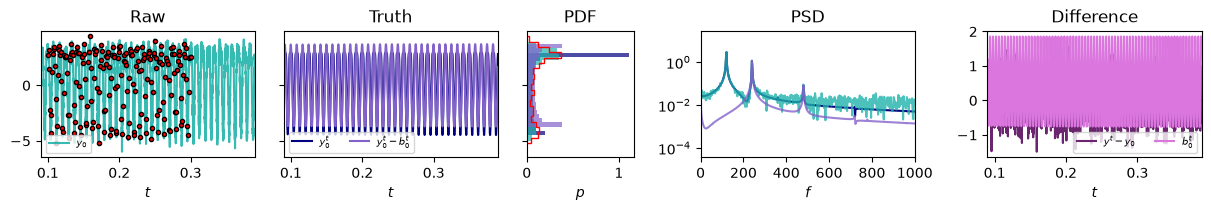

In [2]:
from romda.observations import Observations
from romda.models.physical import VdP
import numpy as np
rng = np.random.default_rng(0)



# The manual bias is a function of state and/or time
def manual_bias(y, t):
    # Linear function of the state
    # return .2 * y + .3 * np.max(y, axis=0), 'linear'
    # Periodic function of the state
    return 0.5 * np.max(y, axis=0) * np.cos(2 * y / np.max(y, axis=0)), 'periodic'
    # Time-varying bias
    # return .4 * y * np.sin((np.expand_dims(t, -1) * np.pi * 2) ** 2), 'time'
    # return 0.*y, 'None'


truth = Observations(model=VdP, 
                     t_min=0.5,
                    t_start=0.6,
                    t_stop=.8,
                    psi0=np.array([2., 1.]),
                    t_max=1.5,
                    Nt_obs=10,
                    add_noise=True,
                    noise_type='gauss, add',
                    noise_level=0.1,
                    manual_bias=manual_bias,
                    include_washout=0
                    )


Observations.plot_truth(truth, f_max=1000)

In [3]:
from romda.utils import set_working_directories
results_folder = set_working_directories('VdP_bias')[1]

### ii. Define ensemble

In [4]:
from romda.estimators import EnSRKF, EnKF, rBA_EnKF



alpha0 = dict(    
            zeta=(40, 50.),
            # beta=(50, 80),
            # kappa=(3, 5),
            )

forecast_model = VdP(dt=truth.dt,)
# alpha0 = dict()

ensemble = rBA_EnKF(results_folder=results_folder, # Folder to save results
                    # Data assimilation parameters
                    bias_regularization=1.,
                    inflation=1.0,
                    # Model parameters
                    parent_model=forecast_model,      
                    m=10,               # Number of ensemble members
                    std_phi=1.5,        # Initial uncertainty in the state
                    std_alpha=alpha0,   # Initial uncertainty in the parameters
                    alpha_distr='uniform',
                    )

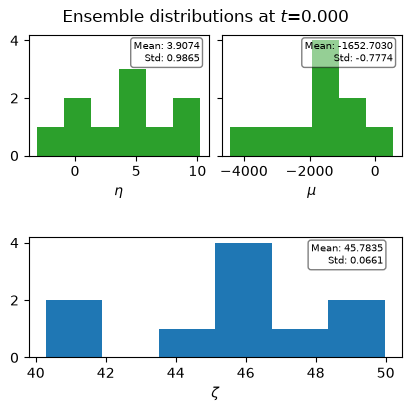

In [5]:
ensemble.visualize_state()

### iii. Train an ESN to model the model bias
The procedure is the following:
- Initialise ESN Bias class object
- Create synthetic bias to use as training data 
- Train the ESN
- Create washout data


In [6]:
from romda.bias_estimators import ESN_bias
import matplotlib.pyplot as plt

plt.close('all')

training_data_filename = f'{results_folder}/Tutorial_13_{truth.name_bias}_bias_noise{truth.noise_level}_stda32'  # Filename to save training data and results
training_data_filename += '99'  # Add suffix to distinguish training data with different options




bias_estimator = ESN_bias(rom=ensemble.model,
                            training_data_filename=training_data_filename,
                            reference_data=truth,
                            # Other options
                            biased_observations=False,
                            correlation_based_training=1,
                            augment_data=2,
                            add_noise=False,
                            perform_test=True,
                            t_train=ensemble.model.t_CR*10,
                            t_val=ensemble.model.t_CR*1.,
                            t_test=ensemble.model.t_CR,
                            upsample=5,
                            N_units=50,
                            N_wash=30,
                            N_func_evals=20,
                            N_folds=4,
                            N_grid=4,
                            rho_range=(0.7, 1.),
                            sigma_in_range=(-5, 0),
                            tikh_range=[1e-12, 1e-10, 1e-8],
                            norm_method='range',
                            random_initialization=True,
                            plot_training=False,
                            force_retrain=True,
                            N_ens=ensemble.m,  # one bias state for each ensemble member
                            L=25,
                            std_alpha= dict(zeta=(40, 50.),
                                            beta=(50, 80),
                                            kappa=(3, 5)),
                            std_phi=1.
                            )  # Initialize bias model

OK: Loaded training dataset for bias model.
Force creating new model (skipping search)...
Training ESN model...


src/romda/models/data_driven/rnns/esn_config.py:401: UserWarning: ESN_model: unknown keyword(s) ['L', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'random_initialization', 'std_alpha', 'std_phi', 'training_record', 'y_model'] ignored
  model = ESN_model(data=data, **kwargs)
src/romda/models/data_driven/rnns/esn.py:191: UserWarning: ESN_model.train: keyword(s) ['L', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'random_initialization', 'std_alpha', 'std_phi', 'training_record', 'y_model'] are not attributes of the network and are ignored (did you mean 'est_alpha' for 'std_alpha'?)
  self.train(train_data=data, plot_training=plot_training, **kwargs)


Configuration saved to ...results/esn_configs/d76db222ab8f479c/esn_config.yaml
Trained matrices saved to ...results/esn_configs/d76db222ab8f479c/trained_matrices.npz


src/romda/models/data_driven/rnns/esn.py:212: UserWarning: ESN_model: keyword(s) ['L', 'add_noise', 'augment_data_length', 'biased_observations', 'keep_fixed_points', 'lag_criterion', 'random_initialization', 'std_alpha', 'std_phi', 'training_record', 'y_model'] are not attributes of the model and are ignored
  Model.__init__(self,


In [7]:
from matplotlib.colors import Normalize
import matplotlib.pyplot as plt

def plot_train_data(truth, bias_data, t_CR):

    L, _, _ = bias_data['data'].shape

    Nt = int(t_CR / truth.dt)
    Nq = truth.y_true.shape[1]

    # Build a common valid time window and select the segment before first observation.
    n_common = min(
        len(truth.t_true),
        truth.y_true.shape[0],
        truth.b_true.shape[0],
        bias_data['y_model'].shape[0],
        bias_data['data'].shape[1],
    )


    t0 = bias_data['y_model'].shape[0]

    yt = truth.y_raw[-t0:-t0+Nt]
    bt = truth.b_true[-t0:-t0+Nt]
    tt = truth.t_true[-t0:-t0+Nt]


    yr = bias_data['y_model'][:Nt].transpose(2, 0, 1)
    br = bias_data['data'][:, :Nt, :Nq]

    if len(tt) == 0:
        raise ValueError('Selected plotting window is empty. Check t_CR and training_data dimensions.')


    RS = []
    for ii in range(L):
        RS.append(np.linalg.norm(br[ii][:, 0]) / np.sqrt(len(yt)))

    RS = np.asarray(RS, dtype=float)
    true_RMS = np.linalg.norm(bt[:, 0]) / np.sqrt(len(yt))

    # Plot training data (single row) --------------------------
    fig = plt.figure(figsize    =[12, 2.7], layout='constrained')
    axs = fig.subplots(1, 2)
    
    # Robust color mapping: clip outliers; if RMS are nearly equal, force distinct member colors.
    if np.ptp(RS) < 1e-12:
        color_values = np.linspace(0.0, 1.0, L)
        norm = Normalize(vmin=0.0, vmax=1.0)
        cmap = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap('viridis'))
        cbar_extend = 'neither'
        cbar_title = 'Member'
    else:
        lo, hi = np.percentile(RS, [5, 95])
        if np.isclose(lo, hi):
            lo = float(np.min(RS))
            hi = float(np.max(RS))
        color_values = np.clip(RS, lo, hi)
        norm = Normalize(vmin=float(lo), vmax=float(hi))
        cmap = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap('viridis'))
        cbar_extend = 'both'
        cbar_title = '$\\mathrm{RMS}$'

    xlim = [tt[0], tt[-1]]

    axs[0].plot(tt, yt[:, 0], color='silver', linewidth=6, alpha=.8)
    axs[1].plot(tt, bt[:, 0], color='silver', linewidth=4, alpha=.8)

    for ii in range(L):
        clr = cmap.to_rgba(color_values[ii])
        axs[0].plot(tt, yr[ii][:, 0], color=clr, alpha=0.7)
        axs[1].plot(tt, br[ii][:, 0], color=clr, alpha=0.7)

    axs[0].legend(['Truth'], bbox_to_anchor=(0., 0.25), loc='upper left')
    axs[1].legend(['True RMS $={0:.3f}$'.format(true_RMS)], bbox_to_anchor=(0., 0.25), loc='upper left')
    axs[0].set(xlabel='$t$', ylabel='$\\eta$', xlim=xlim)
    axs[1].set(xlabel='$t$', ylabel='$b$', xlim=xlim)

    clb = fig.colorbar(cmap, ax=axs, orientation='vertical', extend=cbar_extend)
    clb.ax.set_title(cbar_title)


(50, 4800, 1)


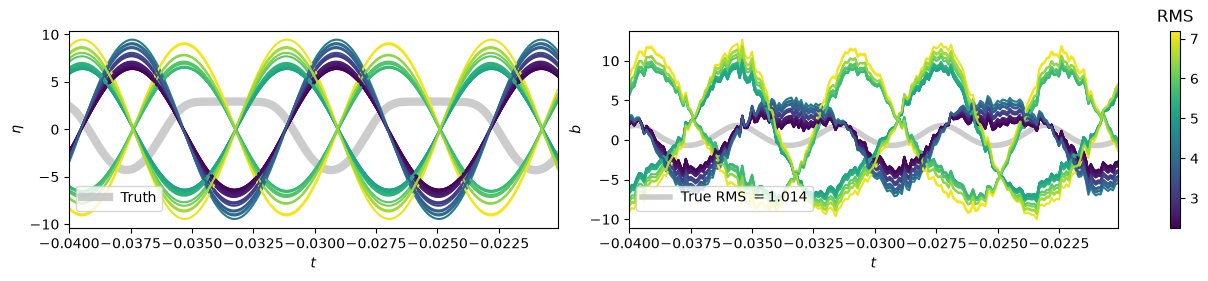

In [8]:

from romda.bias_estimators.aux import plot_train_data
import numpy as np
# training_data_filename = f'{results_folder}/Tutorial_13_{truth.name_bias}_bias_noise{truth.noise_level}'  # Filename to save training data and results


training_data = np.load(f'{training_data_filename}', allow_pickle=True)


plot_train_data(truth, training_data, t_CR=0.02)
print(training_data['data'].shape)


### iv. Run DA cycle


In [9]:
# Observation covariance matrix (consistent with main branch)
std_obs = 0.01
Cdd = np.diag(std_obs * np.ones(ensemble.model.Nq)) * np.max(abs(truth.y_obs), axis=0) ** 2


In [10]:
filter_ens = ensemble.copy()
filter_ens.bias = bias_estimator.copy() 
filter_ens.regularization_factor = 1.
filter_ens.inflation_factor_rejection = 1.
filter_ens.start_bias = 0
ii = -1

J = []
inn = []
inn_t = []

for d, t_d in zip(truth.y_obs, truth.t_obs):
    ii += 1
    if ii % 4 == 0:
        print(f'Assimilation step {ii}, time {t_d:.3f}')

        filter_ens.forecast_step(t_end=t_d.copy())
        # J.append(filter_ens.bias.state_derivative())
        y = filter_ens.model.get_observables()
        # bias_state = filter_ens.bias.update_state_from_innovation(d - y)  # Innovation is observation minus analysis
        inn.append(d - y)
        inn_t.append(t_d)
        # filter_ens.bias.update_history(bias_state, # Innovation (observation - analysis)
        #                             filter_ens.current_time, modify_saved_states=True)

        b = filter_ens.bias.get_innovations(filter_ens.bias.current_bias)
        print('shapes', d.shape, y.shape, inn[-1].shape)
        print('bias', b.shape)
        # raise NotImplementedError('Bias update not implemented yet. This is a placeholder for the bias update step, which will be added in future iterations of the code. The bias update will involve using the innovation (observation minus analysis) to update the bias state, and then applying this updated bias state to correct the forecast before the analysis step.')

        filter_ens.analysis_step(d=d.copy(), Cdd=Cdd.copy())
        
        if ii > 100:
            break
    


Assimilation step 0, time 0.100


shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 4, time 0.104
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 8, time 0.108
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 12, time 0.112
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 16, time 0.116
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 20, time 0.120
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 24, time 0.124
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 28, time 0.128
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 32, time 0.132
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 36, time 0.136
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 40, time 0.140


shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 44, time 0.144
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 48, time 0.148
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 52, time 0.152
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 56, time 0.156
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 60, time 0.160
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 64, time 0.164
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 68, time 0.168
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 72, time 0.172
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 76, time 0.176
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 80, time 0.180
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 84, time 0.184
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 88, time 0.188
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 92, time 0.192
shapes (1,) 

shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 100, time 0.200
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)
Assimilation step 104, time 0.204
shapes (1,) (1, 10) (1, 10)
bias (1, 1, 1)


(0.15, 0.2)

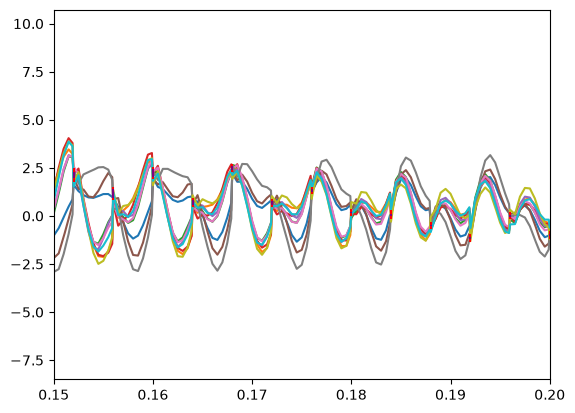

In [11]:
plt.plot(filter_ens.bias.hist_t, filter_ens.bias.get_innovations(state=filter_ens.bias.hist)[:, 0], label='Bias estimate')

inn_array = np.array(inn)[:, 0]
conv_inn = inn_array - np.mean(inn_array, axis=-1, keepdims=True)  # Centered innovations (obs_dim, Nens)
cov_inn = np.cov(conv_inn, rowvar=True)  # Full covariance of innovations (obs_dim, obs_dim)

cov_inn_2 = np.cov(conv_inn, rowvar=True)  # Full covariance of centered innovations (obs_dim, obs_dim)

plt.errorbar(np.array(inn_t), np.mean(inn_array, axis=-1), yerr=np.std(conv_inn, axis=-1), label='Observations', c='r', ls='')
plt.errorbar(np.array(inn_t), np.mean(inn_array, axis=-1), yerr=np.std(cov_inn_2, axis=-1), label='Observations', c='b', ls='', alpha=0.5)

plt.xlim(0.15, 0.2)

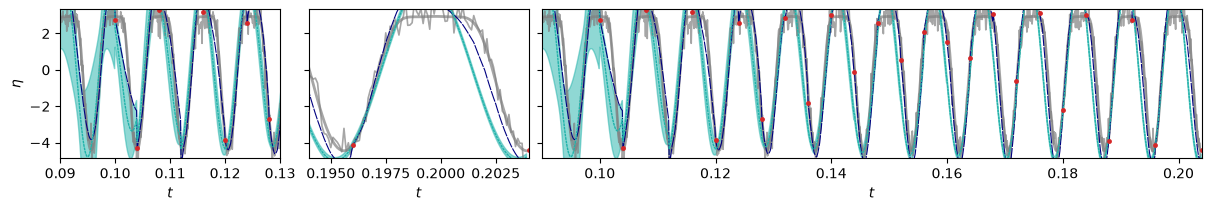

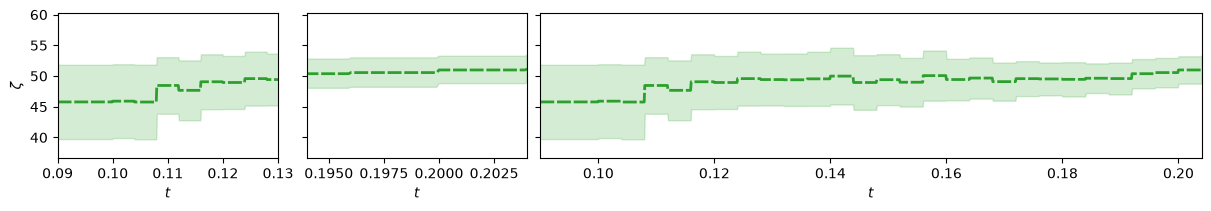

In [12]:
filter_ens.visualize_history(truth=truth)

### v. Plot results


___

#### Exercise 

<em><font color="#7CB9E8">&emsp; How does the solution change as we vary the  bias regularization factor, $\gamma$ ? What happens if $\gamma=0$? And if  $\gamma=25$? </font></em>

___

<BarContainer object of 50 artists>

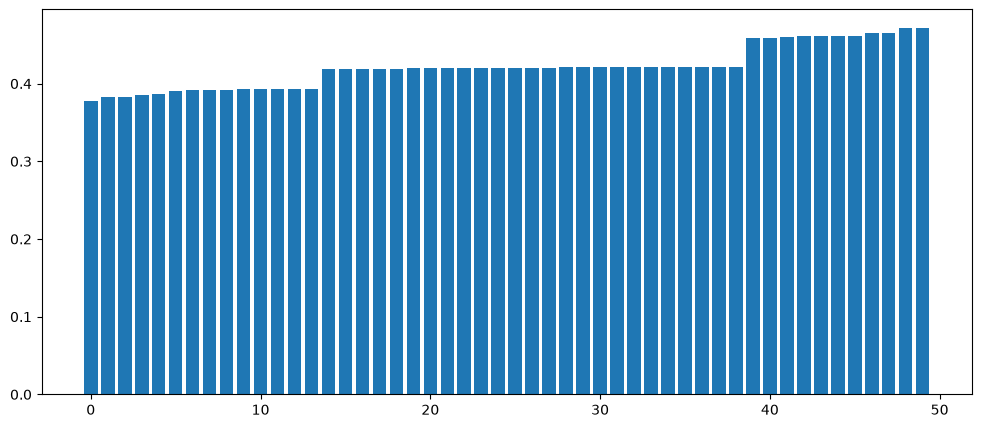

In [13]:
# Check the training data and results
training_data = np.load(f'{training_data_filename}', allow_pickle=True)
data = training_data.get('data')
data.shape

b_prediction = filter_ens.bias.get_bias_hist(mean=True)
plt.figure(figsize=(12, 5))
time = truth.t_true[:len(data[1])] - truth.t_true[0]
# plt.plot(time, truth.b_true[:len(data[1]), 0], label='True bias', c='k', lw=2)
zeros = np.zeros_like(data[...,0]) + np.mean(data[...,0], axis=1, keepdims=True)

plt.bar(np.arange(data.shape[0]), sorted(np.mean(data[...,0], axis=1)))
# plt.plot(time, zeros.T, label='Training data', alpha=0.5)
# plt.plot(filter_ens.bias.hist_t-filter_ens.bias.hist_t[0], b_prediction[:, 0], label='Predicted bias', c='r', lw=2
# log lims
# plt.gca().set_yscale('log')

# plt.xlim(time[0], time[500])